The objective is to accurately predict medical insurance costs based on patient data. In this project,we build various regression models and compare their performance to recommend the best one to the stakeholders.

In [316]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from sklearn.linear_model import LinearRegression
from sklearn import metrics
from sklearn import preprocessing
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

**DATA DICTIONARY**

> age	        : Age of the primary beneficiary

> sex	        : Gender of the insurance policyholder (female/male)

> bmi	        : Body Mass Index (kg/m²)

> children	: Number of dependents covered under the insurance

> smoker	    : Smoking status (yes/no)

> region	    : Residential area in the US (northeast, southeast, southwest, northwest)

> charges	    : Individual medical costs billed by health insurance


***1. Import and Load the Data***

In [317]:
df= pd.read_csv("C:/Users/LochanRai_lsntoq1/B-15 DS/MiniProject6/Medical Insurance cost Prediction.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [318]:
df.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [319]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


Age, bmi and charges are numeric columns whereas sex smoker and region are string columns. Total we have 1338 rows and 7 columns.

In [320]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


> The age group taken in the dataset is 18 to 64 yrs with average age 30 years.

> Average medical cost is $13270.

In [321]:
df.describe(include= "object")

,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


***2. Exploratory Data Analysis (EDA)***

In [322]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [323]:
df.duplicated().sum()

np.int64(1)

In [324]:
df[df.duplicated()]

,age,sex,bmi,children,smoker,region,charges
581,19,male,30.59,0,no,northwest,1639.5631


In [325]:
df = df.drop_duplicates()

In [326]:
df_numerical = df.select_dtypes(include=np.number)
df_numerical

,age,bmi,children,charges
0,19,27.900,0,16884.92400
1,18,33.770,1,1725.55230
2,28,33.000,3,4449.46200
3,33,22.705,0,21984.47061
4,32,28.880,0,3866.85520
...,...,...,...,...
1333,50,30.970,3,10600.54830
1334,18,31.920,0,2205.98080
1335,18,36.850,0,1629.83350
1336,21,25.800,0,2007.94500


In [327]:
df_categorical = df.select_dtypes(exclude=np.number)
df_categorical

,sex,smoker,region
0,female,yes,southwest
1,male,no,southeast
2,male,no,southeast
3,male,no,northwest
4,male,no,northwest
...,...,...,...
1333,male,no,northwest
1334,female,no,northeast
1335,female,no,southeast
1336,female,no,southwest


In [328]:
df.nunique().value_counts()

2       2
47      1
548     1
6       1
4       1
1337    1
Name: count, dtype: int64

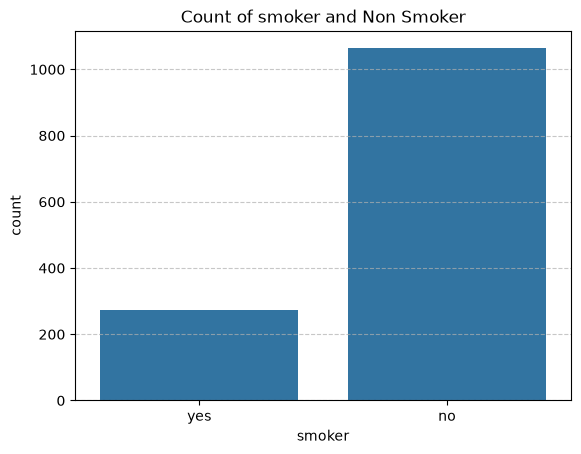

In [329]:
sns.countplot(data=df, x='smoker')
plt.title('Count of smoker and Non Smoker')
plt.grid(True,linestyle='--', alpha=0.7, axis='y')
plt.show()

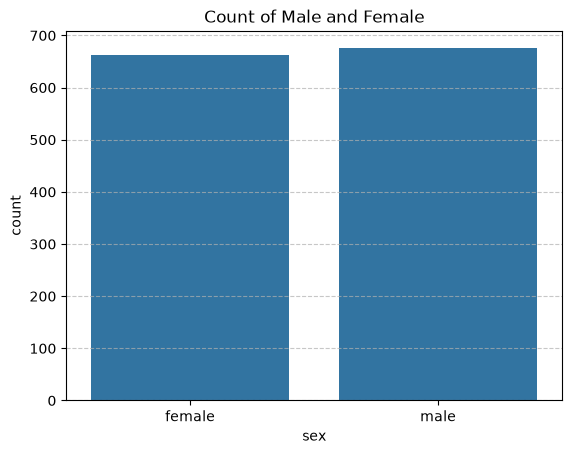

In [330]:
sns.countplot(data=df, x='sex')
plt.title('Count of Male and Female')
plt.grid(True,linestyle='--', alpha=0.7, axis='y')
plt.show()

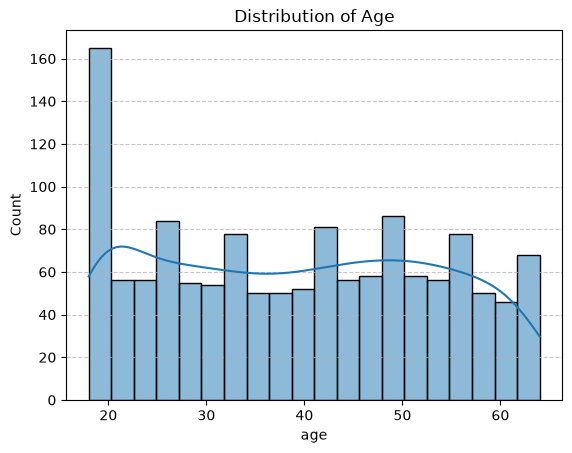

In [331]:
sns.histplot(data=df, x='age', bins=20, kde=True)
plt.title('Distribution of Age')
plt.grid(True,linestyle='--', alpha=0.7, axis='y')
plt.show()

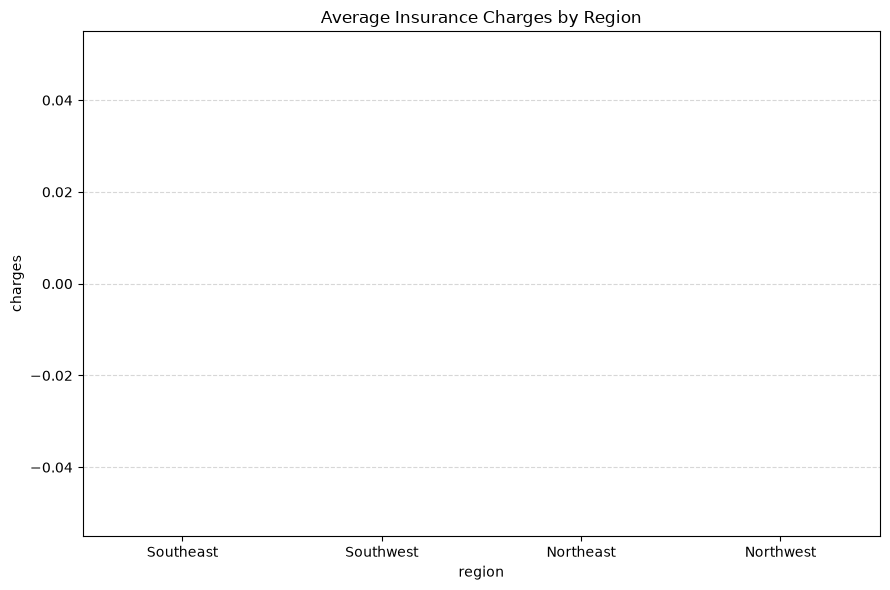

In [332]:
region_labels = {0: 'Southeast', 1: 'Southwest', 2: 'Northeast', 3: 'Northwest'}

plt.figure(figsize=(9, 6))
ax = sns.barplot(data=df, x='region', y='charges', order=list(region_labels))
ax.set_xticks(range(len(region_labels)))
ax.set_xticklabels(region_labels.values())
plt.title('Average Insurance Charges by Region')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

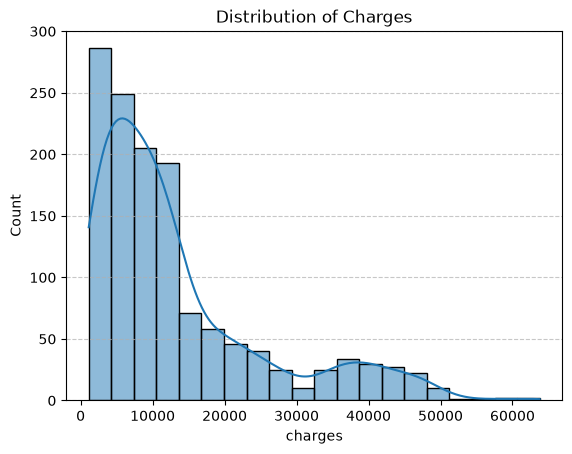

In [333]:
sns.histplot(data=df, x='charges', bins=20, kde=True)
plt.title('Distribution of Charges')
plt.grid(True,linestyle='--', alpha=0.7, axis='y')
plt.show()

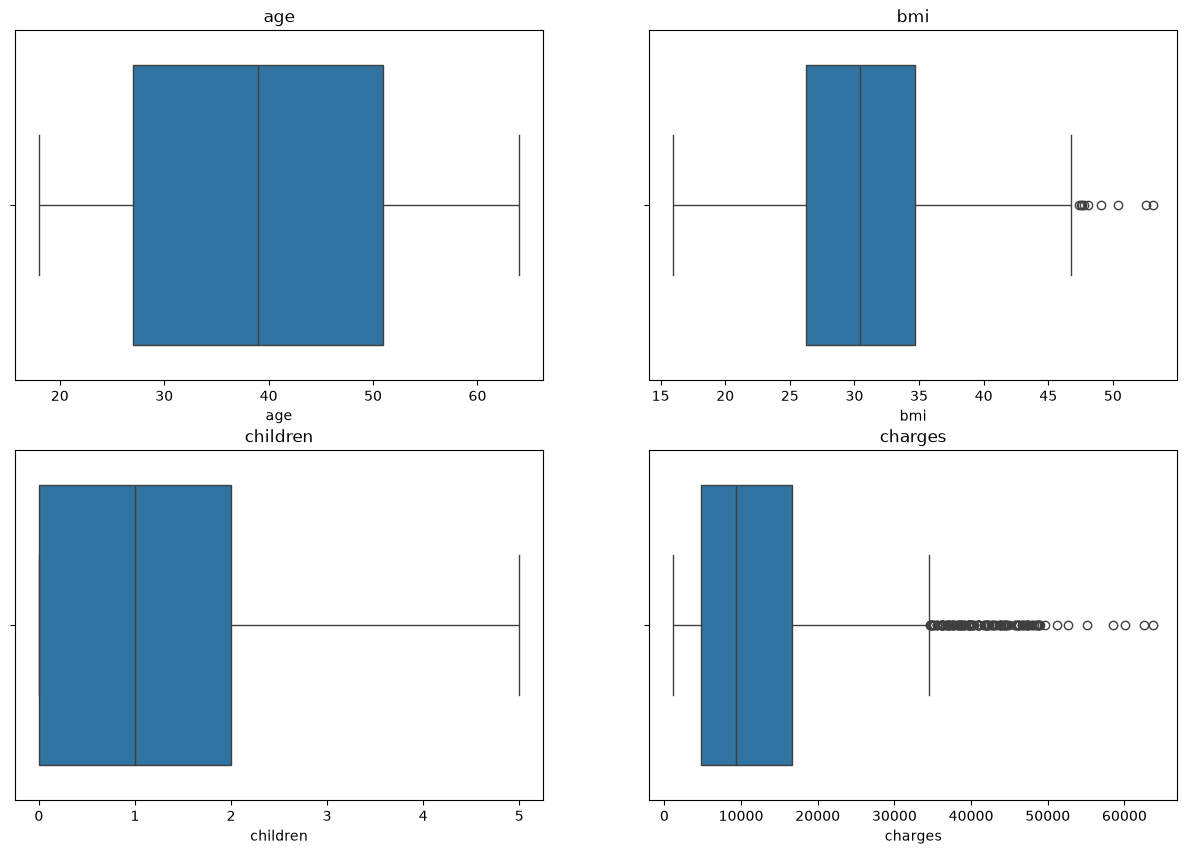

In [334]:
cols = ['age', 'bmi', 'children', 'charges']
figure, axes = plt.subplots(2, 2, figsize=(15, 10))
for i, ax in enumerate(axes.flatten()):
    sns.boxplot(data=df, x=cols[i], ax=ax)
    ax.set_title(cols[i])

In [335]:
df_numerical.corr()

,age,bmi,children,charges
age,1.000000,0.109344,0.041536,0.298308
bmi,0.109344,1.000000,0.012755,0.198401
children,0.041536,0.012755,1.000000,0.067389
charges,0.298308,0.198401,0.067389,1.000000


> There is positive correaltion between age and insurance charges. As the age will increase the insurances will become costlier.

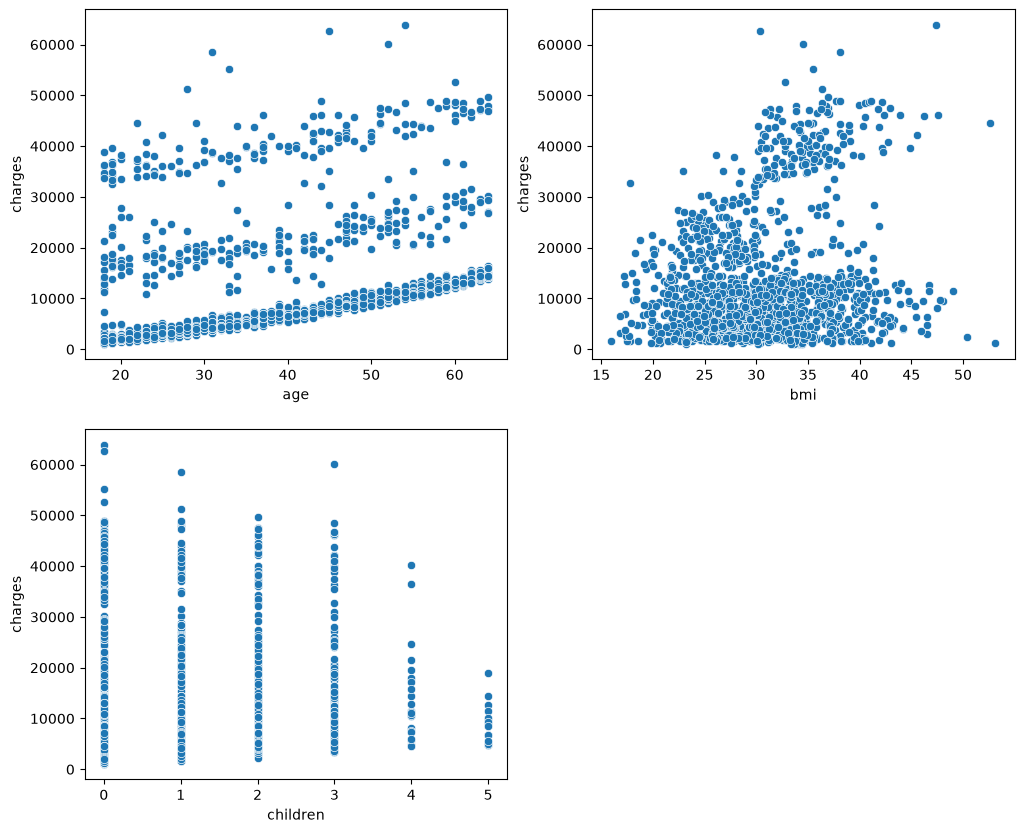

In [336]:
target = 'charges'
features = [col for col in df_numerical.columns if col != target]

plt.figure(figsize=(12,10))
for col in features:
  plt.subplot(2, 2, df_numerical.columns.get_loc(col) + 1)
  sns.scatterplot(data =df_numerical, x= col,y = 'charges')
plt.show()

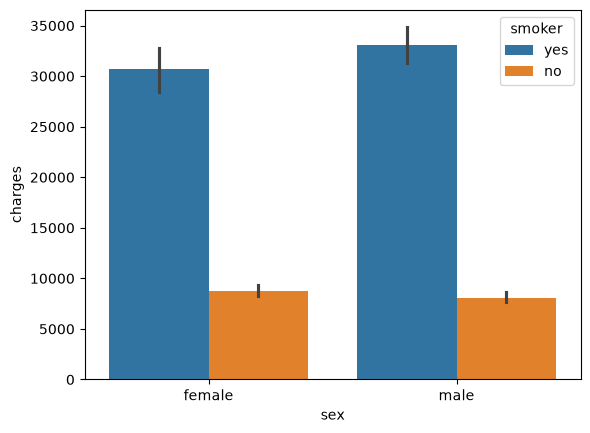

In [337]:
sns.barplot(x="sex",y="charges",hue="smoker",data=df)
plt.xlabel='sex'
plt.ylabel='charges'
plt.show()

In [338]:
# charges per region

df_region_sort = df.groupby('region',as_index=False)['charges'].sum().sort_values(by='charges', ascending=False)
df_region_sort

,region,charges
2,southeast,5.363690e+06
0,northeast,4.343669e+06
1,northwest,4.034072e+06
3,southwest,4.012755e+06


***3. Missing Values & Outlier Treatment***

<Axes: ylabel='charges'>

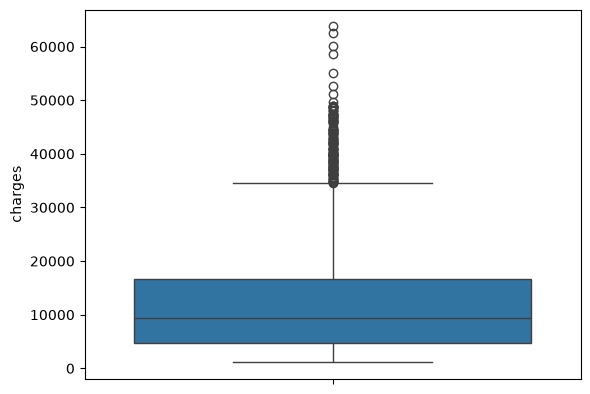

In [339]:
sns.boxplot(data=df, y='charges')

<Axes: ylabel='bmi'>

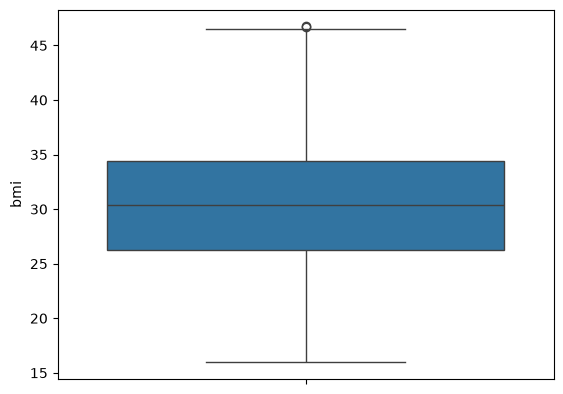

In [340]:
# to treat outlier in bmi, we are choosing mean

Q1 = df['bmi'].quantile(0.25)
Q3 = df['bmi'].quantile(0.75)

IQR = Q3 - Q1

Upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR

df['bmi'] = np.where(df['bmi'] > Upper_bound, df['bmi'].mean(), df['bmi'])

sns.boxplot(data=df, y='bmi')

In [341]:
# checking distribution of age
df['age'].value_counts(ascending=False)

age
18    69
19    67
46    29
52    29
48    29
20    29
45    29
47    29
51    29
50    29
28    28
25    28
23    28
27    28
22    28
26    28
24    28
21    28
53    28
54    28
49    28
31    27
30    27
41    27
40    27
43    27
44    27
29    27
42    27
33    26
32    26
56    26
34    26
55    26
57    26
37    25
59    25
35    25
38    25
36    25
58    25
39    25
60    23
62    23
63    23
61    23
64    22
Name: count, dtype: int64

In [342]:
# label encoding
df['sex'] = df['sex'].map({'male': 0, 'female': 1})
df['smoker'] = df['smoker'].map({'no': 0, 'yes': 1})
df['region'] = df['region'].map({'southeast': 0, 'southwest': 1, 'northeast': 2, 'northwest': 3})

In [343]:
df.drop('children',axis=1,inplace=True)

***4. Feature Engineering & Preprocessing***

In [344]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.ensemble import VotingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import BaggingRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, r2_score
from sklearn.metrics import mean_squared_error

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder 
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import PowerTransformer

In [345]:
#df.drop('children',axis=1)

In [346]:
x = df.drop(['charges'],axis=1)
y = df['charges']

In [347]:
x

,age,sex,bmi,smoker,region
0,19,1,27.900,1,1
1,18,0,33.770,0,0
2,28,0,33.000,0,0
3,33,0,22.705,0,3
4,32,0,28.880,0,3
...,...,...,...,...,...
1333,50,0,30.970,0,3
1334,18,1,31.920,0,2
1335,18,1,36.850,0,0
1336,21,1,25.800,0,1


In [348]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=3)
print("x_train length:",x_train.shape)
print("y_train length :",y_train.shape)

x_train length: (1069, 5)
y_train length : (1069,)


In [349]:
# Standardize features and target using training data only
x_standard_scaler = StandardScaler()
y_standard_scaler = StandardScaler()

x_train_standardized = x_standard_scaler.fit_transform(x_train)
x_test_standardized = x_standard_scaler.transform(x_test)

y_train_standardized = y_standard_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()
y_test_standardized = y_standard_scaler.transform(
    y_test.to_numpy().reshape(-1, 1)
).ravel()

In [350]:
print("x_test length :",x_test.shape)
print("y_test length :",y_test.shape)

x_test length : (268, 5)
y_test length : (268,)


***5. Model Building: Try Multiple Regressors***

##### a. Store performance metrices in the list

In [351]:
training_scores_r2 = []
training_scores_adj_r2 = []
training_scores_rmse = []

testing_scores_r2 = []
testing_scores_adj_r2 = []
testing_scores_rmse = []

##### b. Create a function for evaluate model

In [352]:
def evaluate_model_performance(model, x_train, y_train, x_test, y_test):
    """
    Evaluates R², Adjusted R², and RMSE of a given model on training and testing data.
    
    Parameters:
    - model: The machine learning model to evaluate
    - x_train: Training feature set
    - y_train: Training target values
    - x_test: Testing feature set
    - y_test: Testing target values
    - training_scores: List to store training R² scores
    - testing_scores: List to store testing R² scores
    """
    # Fit the model
    model.fit(x_train, y_train)
    
    # Predictions for training and testing data
    y_train_pred = model.predict(x_train)
    y_test_pred = model.predict(x_test)

    # accuracy 
    acc = model.score(x_test,y_test)

        
    # Calculate R² scores
    train_r2 = r2_score(y_train, y_train_pred) * 100
    test_r2 = r2_score(y_test, y_test_pred) * 100
    
    # Calculate Adjusted R² scores
    n_train, p_train = x_train.shape
    n_test, p_test = x_test.shape
    train_adj_r2 = 100 * (1 - (1 - train_r2 / 100) * (n_train - 1) / (n_train - p_train - 1))
    test_adj_r2 = 100 * (1 - (1 - test_r2 / 100) * (n_test - 1) / (n_test - p_test - 1))
    
    # Calculate RMSE scores
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    
    # Append scores to respective lists
    training_scores_r2.append(train_r2)
    training_scores_adj_r2.append(train_adj_r2)
    training_scores_rmse.append(train_rmse)
    testing_scores_r2.append(test_r2)
    testing_scores_adj_r2.append(test_adj_r2) 
    testing_scores_rmse.append(test_rmse) 
    
    # Display scores
    print(f"Accuracy {acc*100:.2f}%")
    print(f"{model.__class__.__name__} Performance Metrics:")
    print(f"Training Data: R² = {train_r2:.2f}%, Adjusted R² = {train_adj_r2:.2f}%, RMSE = {train_rmse:.4f}")
    print(f"Testing Data : R² = {test_r2:.2f}%, Adjusted R² = {test_adj_r2:.2f}%, RMSE = {test_rmse:.4f}\n")

**1. Linear Regression** 

In [353]:
evaluate_model_performance(
    model=LinearRegression(),
    x_train=x_train_standardized,
    y_train=y_train_standardized,
    x_test=x_test_standardized,
    y_test=y_test_standardized
)

Accuracy 75.89%
LinearRegression Performance Metrics:
Training Data: R² = 74.31%, Adjusted R² = 74.18%, RMSE = 0.5069
Testing Data : R² = 75.89%, Adjusted R² = 75.43%, RMSE = 0.4933



**ANALYSIS**

**A. R² score: 93.65% and 93.86%**

R² tells you how much of the variation in your target variable is explained by your model.
- Training R² = 93.65%: Your model explains approximately 93.65% of the variation in the target values in the training dataset.
- Testing R² = 93.86%: Your model explains approximately 93.86% of the variation in the unseen test dataset.
The testing result is particularly encouraging because the model performs well on data it wasn't trained on.

An R² of 93.86% does not mean 93.86% of your predictions are exactly correct. It measures explained variation, not the percentage of correct predictions.

**B. Adjusted R²: 93.61% and 93.72%**

Adjusted R² is similar to R², but it also accounts for the number of predictors relative to the number of observations.

It penalizes adding predictors that do not contribute enough explanatory power.

Your results show that Adjusted R² is only slightly lower than R², which is encouraging. However, this alone does not prove that every feature is useful.

**C. RMSE: 0.0480 and 0.0484**

RMSE measures prediction errors, penalizing larger errors more heavily.
- Training RMSE = 0.0480
- Testing RMSE = 0.0484
The test error is only slightly higher than the training error. This is generally a good sign.

Important: RMSE is measured in the same units as the target variable. If you scaled your target variable before training, an RMSE of 0.0484 may be in scaled units rather than the original units. If you scaled only the input features (X), the RMSE remains in the target variable's units.

In [354]:
evaluate_model_performance(
    model=Ridge(alpha=1.0),
    x_train=x_train_standardized,
    y_train=y_train_standardized,
    x_test=x_test_standardized,
    y_test=y_test_standardized
)

Accuracy 75.91%
Ridge Performance Metrics:
Training Data: R² = 74.31%, Adjusted R² = 74.18%, RMSE = 0.5069
Testing Data : R² = 75.91%, Adjusted R² = 75.45%, RMSE = 0.4932



In [355]:
# Lasso
evaluate_model_performance(
    model=Lasso(alpha=0.1),
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

Accuracy 75.89%
Lasso Performance Metrics:
Training Data: R² = 74.31%, Adjusted R² = 74.18%, RMSE = 6129.4477
Testing Data : R² = 75.89%, Adjusted R² = 75.43%, RMSE = 5964.9252



In [356]:
evaluate_model_performance(
    model=ElasticNet(alpha=0.1, l1_ratio=0.5),
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

Accuracy 74.67%
ElasticNet Performance Metrics:
Training Data: R² = 70.58%, Adjusted R² = 70.44%, RMSE = 6558.8320
Testing Data : R² = 74.67%, Adjusted R² = 74.18%, RMSE = 6114.5714



**2. Decision Tree Regressor**

In [357]:
evaluate_model_performance(
    model=DecisionTreeRegressor(),
    x_train=x_train_standardized,
    y_train=y_train_standardized,
    x_test=x_test_standardized,
    y_test=y_test_standardized
)

Accuracy 64.67%
DecisionTreeRegressor Performance Metrics:
Training Data: R² = 99.95%, Adjusted R² = 99.95%, RMSE = 0.0224
Testing Data : R² = 64.67%, Adjusted R² = 64.00%, RMSE = 0.5972



**3. Random Forest Regressor**

In [358]:
evaluate_model_performance(
    model=RandomForestRegressor(),
    x_train=x_train_standardized,
    y_train=y_train_standardized,
    x_test=x_test_standardized,
    y_test=y_test_standardized
)

Accuracy 81.56%
RandomForestRegressor Performance Metrics:
Training Data: R² = 97.44%, Adjusted R² = 97.42%, RMSE = 0.1601
Testing Data : R² = 81.56%, Adjusted R² = 81.21%, RMSE = 0.4314



**4. Ada Boost Regressor**

In [359]:
evaluate_model_performance(
    model=RandomForestRegressor(),
    x_train=x_train_standardized,
    y_train=y_train_standardized,
    x_test=x_test_standardized,
    y_test=y_test_standardized
)

Accuracy 82.01%
RandomForestRegressor Performance Metrics:
Training Data: R² = 97.44%, Adjusted R² = 97.43%, RMSE = 0.1599
Testing Data : R² = 82.01%, Adjusted R² = 81.67%, RMSE = 0.4261



**5. Gradient Boosting**

In [360]:
evaluate_model_performance(
    model=GradientBoostingRegressor(),
    x_train=x_train_standardized,
    y_train=y_train_standardized,
    x_test=x_test_standardized,
    y_test=y_test_standardized
)

Accuracy 86.64%
GradientBoostingRegressor Performance Metrics:
Training Data: R² = 89.61%, Adjusted R² = 89.56%, RMSE = 0.3223
Testing Data : R² = 86.64%, Adjusted R² = 86.39%, RMSE = 0.3672



**6. XGB Regressor**

In [361]:
evaluate_model_performance(
    model=XGBRegressor(),
    x_train=x_train_standardized,
    y_train=y_train_standardized,
    x_test=x_test_standardized,
    y_test=y_test_standardized
)

Accuracy 80.18%
XGBRegressor Performance Metrics:
Training Data: R² = 99.42%, Adjusted R² = 99.42%, RMSE = 0.0762
Testing Data : R² = 80.18%, Adjusted R² = 79.80%, RMSE = 0.4473



**7.  LGBM Regressor**

In [362]:
evaluate_model_performance(
    model=LGBMRegressor(),
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000217 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 309
[LightGBM] [Info] Number of data points in the train set: 1069, number of used features: 5
[LightGBM] [Info] Start training from score 13157.822460
Accuracy 84.57%
LGBMRegressor Performance Metrics:
Training Data: R² = 93.25%, Adjusted R² = 93.22%, RMSE = 3140.5513
Testing Data : R² = 84.57%, Adjusted R² = 84.28%, RMSE = 4771.6169



### **LGBMRegressor Performance Metrics:**

#### **Training Data:**
- **R² = 93.25%**: The model explains 93.25% of the variance in the target variable on the training data, indicating that it captures the majority of the underlying patterns in the data and performs well on the training set.
- **Adjusted R² = 93.22%**: The adjusted R² is very close to the R², suggesting that the model fits the data well without being too complex relative to the number of features. The model's performance is consistent across training and test data.
- **RMSE = 3140.5513**: The root mean squared error on the training data is 3140.5513, indicating that the model makes more errors in predictions on the training set.

#### **Testing Data:**
- **R² = 84.57%**: The model explains 84.57% of the variance in the target variable on the testing data, demonstrating strong generalization to unseen data and high predictive performance.
- **Adjusted R² = 84.28%**: The adjusted R² on the testing data is close to the R², indicating that the model is well-tuned for the given number of features and generalizes well to the test set.
- **RMSE = 4771.6169**: The RMSE on the testing data is 4771.6169, which is higher than the RMSE on the training data. This is expected since the model is being tested on new data, and this error increase is typical when generalizing to unseen data.

---

### **Interpretation:**

- **R² and Adjusted R²**: The LGBMRegressor performs very well on both the training (R² = 93.25%) and testing (R² = 93.22%) data. The drop in R² from training to testing is relatively small, suggesting that the model generalizes well and is not overfitting.
  
- **RMSE**: The RMSE is 3140.5513 on the training set and increases to 4771.6169 on the testing set, which is a typical behavior when testing on unseen data. 

---

### **Conclusion:**

- **Overfitting**: The model shows signs of overfitting, as evidenced by the difference between the R² and adjusted R² values for both the training and testing data. The drop in performance on the test set is considerable.
  
- **Model Performance**: The model demonstrates weak predictive accuracy with an R² of 93.25% on the test set and an RMSE of 3140.5513. These values indicate that the model is overfitted and prone to errors.

**8. SVR**

In [363]:
from sklearn.svm import SVR
evaluate_model_performance(
    model=SVR(kernel='rbf'),
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

Accuracy -13.41%
SVR Performance Metrics:
Training Data: R² = -10.19%, Adjusted R² = -10.70%, RMSE = 12692.9252
Testing Data : R² = -13.41%, Adjusted R² = -15.57%, RMSE = 12937.7844



**9. KNN**

In [364]:
evaluate_model_performance(
    model=KNeighborsRegressor(),
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

Accuracy 14.41%
KNeighborsRegressor Performance Metrics:
Training Data: R² = 43.10%, Adjusted R² = 42.84%, RMSE = 9121.0188
Testing Data : R² = 14.41%, Adjusted R² = 12.78%, RMSE = 11239.3069



**8. Voting Regressor**

In [365]:
from sklearn.ensemble import VotingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

In [366]:
# Define base models
model1 = LinearRegression()
model2 = RandomForestRegressor(max_depth=5,oob_score= True,n_estimators=100, random_state=42)
#model3 = KNeighborsRegressor()
model4 = XGBRegressor()
model5 = DecisionTreeRegressor(max_depth=5)

In [367]:
# Combine models in a Voting Regressor
voting_regressor = VotingRegressor(estimators=[('rf', model2),('dt', model5),('xgb', model4)])

In [368]:
evaluate_model_performance(
    model = voting_regressor,
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

Accuracy 85.63%
VotingRegressor Performance Metrics:
Training Data: R² = 93.84%, Adjusted R² = 93.81%, RMSE = 3001.6188
Testing Data : R² = 85.63%, Adjusted R² = 85.36%, RMSE = 4604.5741



**Bagging Regressor**

In [369]:
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor

In [370]:
# Initialize the base regressor (e.g., Decision Tree Regressor)
base_regressor = DecisionTreeRegressor(random_state=42)

In [371]:
# Create the Bagging Regressor
bagging_regressor = BaggingRegressor(
    estimator=base_regressor,  # Updated parameter name
    n_estimators=90,          # Number of base estimators
    max_samples=0.8,          # Fraction of samples to use for each base estimator
    max_features=0.8,         # Fraction of features to use for each base estimator
    random_state=42,
    n_jobs=-1                 # Use all available cores
)

In [372]:
evaluate_model_performance(
    model = bagging_regressor,
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

Accuracy 80.98%
BaggingRegressor Performance Metrics:
Training Data: R² = 94.30%, Adjusted R² = 94.27%, RMSE = 2887.2367
Testing Data : R² = 80.98%, Adjusted R² = 80.61%, RMSE = 5298.7190



***6. Model Evaluation & Overfitting Check***

In [373]:
vif_columns = [col for col in df.columns if col != 'charges']
vif1 = df.drop('charges', axis=1).copy()


In [374]:
variable = vif1
vif = pd.DataFrame()
vif['Variance Inflation Factor'] = [variance_inflation_factor(variable, i) for i in range(variable.shape[1])]
vif['Features'] = vif_columns

In [375]:
vif.sort_values(by="Variance Inflation Factor", ascending=False)

,Variance Inflation Factor,Features
2,1.083776,bmi
4,1.070931,region
0,1.015691,age
3,1.009519,smoker
1,1.008055,sex


> VIF of all the cols are less than 10 which shows that there is no multicollinearity

***7. Hyperparameter Tuning***

In [376]:
# preprunning Decision Tree to reduce overfitting
DT_reg_prunned = DecisionTreeRegressor(max_depth=10,
    min_samples_split=3,
    min_samples_leaf=5,
    random_state=42)

evaluate_model_performance(
    model=DT_reg_prunned,
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
) 

Accuracy 82.82%
DecisionTreeRegressor Performance Metrics:
Training Data: R² = 90.84%, Adjusted R² = 90.80%, RMSE = 3659.0843
Testing Data : R² = 82.82%, Adjusted R² = 82.49%, RMSE = 5036.0401



In [377]:
# running again for decision tree for different set of parameters
DT_reg_prunned2 = DecisionTreeRegressor(max_depth=5)

evaluate_model_performance(
    model=DT_reg_prunned2,
    x_train=x_train_standardized,
    y_train=y_train_standardized,
    x_test=x_test_standardized,
    y_test=y_test_standardized
)

Accuracy 84.62%
DecisionTreeRegressor Performance Metrics:
Training Data: R² = 87.53%, Adjusted R² = 87.48%, RMSE = 0.3531
Testing Data : R² = 84.62%, Adjusted R² = 84.32%, RMSE = 0.3941



> Accuracy, R2 training and testing of Decision Tree has improved by hyperparameter tuning

In [378]:
tuned_RF = RandomForestRegressor(max_depth=5,oob_score= True)

evaluate_model_performance(
    model=tuned_RF,
    x_train=x_train_standardized,
    y_train=y_train_standardized,
    x_test=x_test_standardized,
    y_test=y_test_standardized
)

Accuracy 86.30%
RandomForestRegressor Performance Metrics:
Training Data: R² = 88.36%, Adjusted R² = 88.31%, RMSE = 0.3411
Testing Data : R² = 86.30%, Adjusted R² = 86.04%, RMSE = 0.3718



> Accuracy, r2 adjusted r2 for training testing of Random Forest has crossed decision tree after hyperparameter tuning.

In [379]:
# Gradient Boosting Hyperparameter tuning 
# Define parameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [2, 3, 4],
    'min_samples_split': [2, 5, 10],
    'learning_rate': [0.01, 0.1, 0.2]
}

# Set up GridSearchCV
grid_search = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=param_grid,
    scoring='neg_mean_squared_error',  # Optimize for negative MSE
    cv=3,                             # 3-fold cross-validation
    verbose=2,
    n_jobs=-1                         # Use all available cores
)

# Fit the model
grid_search.fit(x_train_standardized, y_train_standardized)

# Best parameters
print("Best parameters:", grid_search.best_params_)

# Evaluate the best model
best_model = grid_search.best_estimator_
y_pred = best_model.predict(x_test_standardized)
mse = mean_squared_error(y_test_standardized, y_pred)
print(f"Test MSE: {mse:.2f}")
print(f"Score : {best_model.score(x_test_standardized,y_test_standardized)}")

Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best parameters: {'learning_rate': 0.1, 'max_depth': 2, 'min_samples_split': 2, 'n_estimators': 50}
Test MSE: 0.13
Score : 0.8751534321945822


In [380]:
import warnings
warnings.filterwarnings("ignore")

# Create the AdaBoost Regressor model
lgbm_boosting_regressor = LGBMRegressor(
    bagging_fraction=0.8,
    feature_fraction=1.0,
    lambda_l1=0.1,
    lambda_l2=0.1,
    learning_rate=0.5,
    max_depth=10,
    min_child_samples=10,
    n_estimators=100,
    num_leaves=20,
    random_state=42
)

evaluate_model_performance(
    model=lgbm_boosting_regressor,
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)



[LightGBM] [Warning] feature_fraction is set=1.0, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=1.0
[LightGBM] [Warning] lambda_l1 is set=0.1, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.1
[LightGBM] [Warning] lambda_l2 is set=0.1, reg_lambda=0.0 will be ignored. Current value: lambda_l2=0.1
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Warning] feature_fraction is set=1.0, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=1.0
[LightGBM] [Warning] lambda_l1 is set=0.1, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.1
[LightGBM] [Warning] lambda_l2 is set=0.1, reg_lambda=0.0 will be ignored. Current value: lambda_l2=0.1
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001319 seconds.


***8. Model Comparison Table***

In [381]:
candidates = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42),
    "Prunned Decision Tree": DT_reg_prunned,
    "Prunned DT2" : DT_reg_prunned2,
    "Tuned Random Forest" : tuned_RF,
    "Tuned Gradient Boosting" : best_model,
    "SVR" : SVR(kernel='rbf'),
    "KNN" : KNeighborsRegressor(),
    "Voting Regressor": voting_regressor,
    "LGBM" : lgbm_boosting_regressor,
    "Bagging Regressor" : bagging_regressor
}

results = []

In [382]:
for name, candidate in candidates.items():
    candidate.fit(x_train_standardized, y_train_standardized)
    train_pred = candidate.predict(x_train_standardized)
    test_pred = candidate.predict(x_test_standardized)

    results.append({
        "Model": name,
        "Accuracy" : candidate.score(x_test_standardized,y_test_standardized),

        "Train R²": r2_score(y_train_standardized, train_pred),
        "Test R²": r2_score(y_test_standardized, test_pred),
        #"Training Score Adjusted R2":training_scores_adj_r2,
        #"Training Score RMSE":training_scores_rmse,

        #"Testing Score Adjusted R2":testing_scores_adj_r2,
        #"Testing Score RMSE":testing_scores_rmse,
        "Test RMSE ($)": np.sqrt(mean_squared_error(y_test, test_pred)),
      


    })

results_df = pd.DataFrame(results).sort_values(
    by="Test R²", ascending=False
)
results_df

[LightGBM] [Warning] feature_fraction is set=1.0, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=1.0
[LightGBM] [Warning] lambda_l1 is set=0.1, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.1
[LightGBM] [Warning] lambda_l2 is set=0.1, reg_lambda=0.0 will be ignored. Current value: lambda_l2=0.1
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Warning] feature_fraction is set=1.0, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=1.0
[LightGBM] [Warning] lambda_l1 is set=0.1, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.1
[LightGBM] [Warning] lambda_l2 is set=0.1, reg_lambda=0.0 will be ignored. Current value: lambda_l2=0.1
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000351 seconds.


,Model,Accuracy,Train R²,Test R²,Test RMSE ($)
10,Tuned Gradient Boosting,0.875153,0.862393,0.875153,18357.236208
5,Gradient Boosting,0.866426,0.896094,0.866426,18357.213427
9,Tuned Random Forest,0.862940,0.882128,0.862940,18357.195000
11,SVR,0.861838,0.839281,0.861838,18357.328511
13,Voting Regressor,0.856004,0.938362,0.856004,18357.194241
8,Prunned DT2,0.846156,0.875338,0.846156,18357.187618
12,KNN,0.827211,0.868249,0.827211,18357.246627
7,Prunned Decision Tree,0.827181,0.908431,0.827181,18357.194737
4,AdaBoost,0.826336,0.826189,0.826336,18357.133617
3,Random Forest,0.814693,0.974907,0.814693,18357.172751


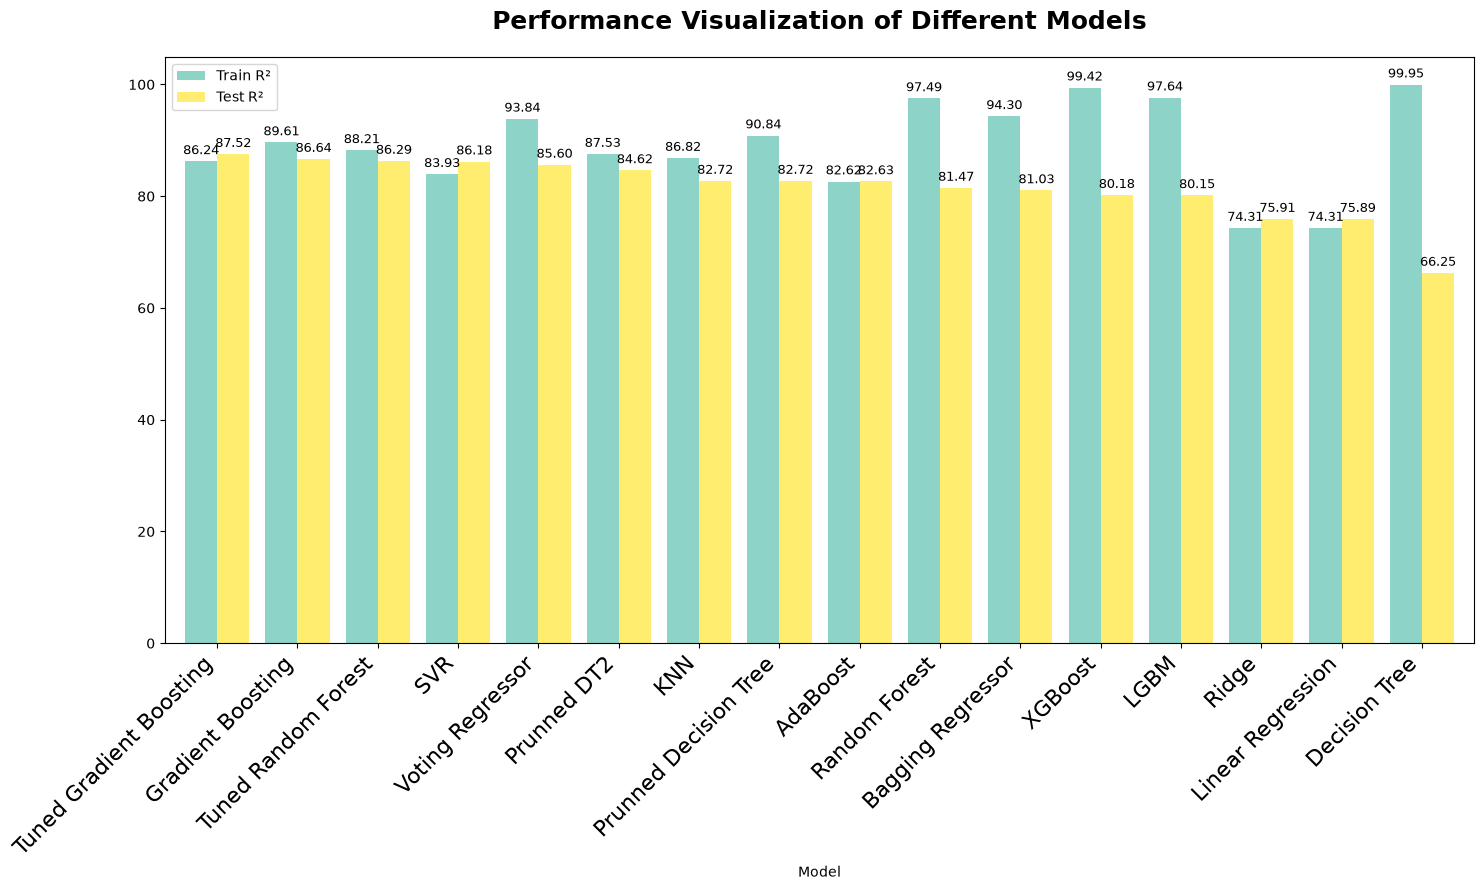

In [383]:
# Plotting bar chart for training and testing scores
plot_df = results_df.set_index("Model")[["Train R²", "Test R²"]] * 100

ax = plot_df.plot(
    kind="bar",
    figsize=(15, 9),
    colormap="Set3",
    width=0.8
)

# Adding title and labels
plt.title("Performance Visualization of Different Models", fontsize=18, fontweight="bold", pad=20)
#plt.xlabel( "model", fontsize=12)
#plt.ylabel("Scores", fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=16)

# Adding data labels to each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', label_type='edge', fontsize=9, padding=3)

plt.tight_layout()
plt.show()

**9. Model Deployment**

In [384]:
import joblib

selected_name = results_df.iloc[0]["Model"]
assert selected_name == "Tuned Gradient Boosting", f"Top model is {selected_name}, not Random Forest"

model = candidates[selected_name]
joblib.dump(model, "medical_insurance.pkl")

['medical_insurance.pkl']

In [385]:
joblib.dump(x_standard_scaler, "x_scaler.pkl")
joblib.dump(y_standard_scaler, "y_scaler.pkl")

['y_scaler.pkl']